In [4]:
import sys
import pandas as pd
import numpy as np
import sklearn
import matplotlib
import plotly
import fastapi
import streamlit

print("Python executable:", sys.executable)
print("Python           :", sys.version.split()[0])
print("pandas           :", pd.__version__)
print("numpy            :", np.__version__)
print("scikit-learn     :", sklearn.__version__)
print("matplotlib       :", matplotlib.__version__)
print("plotly           :", plotly.__version__)
print("fastapi          :", fastapi.__version__)
print("streamlit        :", streamlit.__version__)

Python executable: C:\Users\Suhayb\VitalSense AI Predictive Project\venv\Scripts\python.exe
Python           : 3.13.9
pandas           : 3.0.6
numpy            : 2.5.3
scikit-learn     : 1.9.1
matplotlib       : 3.11.2
plotly           : 7.1.0
fastapi          : 0.143.0
streamlit        : 1.65.0


In [7]:
from pathlib import Path

csv_path = Path("..") / "ai4i+2020+predictive+maintenance+dataset" / "ai4i2020.csv"
print("CSV exists:", csv_path.exists())

df = pd.read_csv(csv_path, encoding="utf-8-sig")

print("Rows   :", df.shape[0])
print("Columns:", df.shape[1])
print(list(df.columns))
df.head()

CSV exists: True
Rows   : 10000
Columns: 14
['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [9]:
print("Data types:")
print(df.dtypes)

print("\nMissing values per column:")
print(df.isnull().sum())

print("\nFully duplicated rows:", df.duplicated().sum())
print("Duplicated UDI       :", df["UDI"].duplicated().sum())
print("Duplicated Product ID:", df["Product ID"].duplicated().sum())

Data types:
UDI                          int64
Product ID                     str
Type                           str
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
Machine failure              int64
TWF                          int64
HDF                          int64
PWF                          int64
OSF                          int64
RNF                          int64
dtype: object

Missing values per column:
UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

Fully duplicated rows: 0
Duplicated 

In [10]:
counts = df["Machine failure"].value_counts()
print(counts)
print(f"\nFailure rate: {df['Machine failure'].mean() * 100:.2f}%")
print(f"Accuracy of a 'never fails' model: {(1 - df['Machine failure'].mean()) * 100:.2f}%")

Machine failure
0    9661
1     339
Name: count, dtype: int64

Failure rate: 3.39%
Accuracy of a 'never fails' model: 96.61%


In [11]:
import numpy as np

# Recompute power from torque and speed
power = df["Torque [Nm]"] * df["Rotational speed [rpm]"] * 2 * np.pi / 60
rule_says_fail = (power < 3500) | (power > 9000)

print("PWF = 1 rows                      :", df["PWF"].sum())
print("PWF = 1 but Machine failure = 0   :", ((df["PWF"] == 1) & (df["Machine failure"] == 0)).sum())
print("\nDoes PWF match the power-range rule?")
print(pd.crosstab(df["PWF"], rule_says_fail, rownames=["PWF"], colnames=["Power outside 3500-9000 W"]))
print(f"\nPower range in data: {power.min():.0f} W to {power.max():.0f} W")

PWF = 1 rows                      : 95
PWF = 1 but Machine failure = 0   : 0

Does PWF match the power-range rule?
Power outside 3500-9000 W  False  True 
PWF                                    
0                           9905      0
1                              0     95

Power range in data: 1148 W to 10470 W


In [13]:
import matplotlib.pyplot as plt

eda = df.rename(columns={
    "Air temperature [K]": "air_temp",
    "Process temperature [K]": "process_temp",
    "Rotational speed [rpm]": "rpm",
    "Torque [Nm]": "torque",
    "Tool wear [min]": "tool_wear",
})
eda["power_w"] = eda["torque"] * eda["rpm"] * 2 * np.pi / 60
eda["temp_diff"] = eda["process_temp"] - eda["air_temp"]

signals = ["air_temp", "process_temp", "rpm", "torque", "tool_wear", "power_w", "temp_diff"]
normal = eda[eda["Machine failure"] == 0]
failed = eda[eda["Machine failure"] == 1]

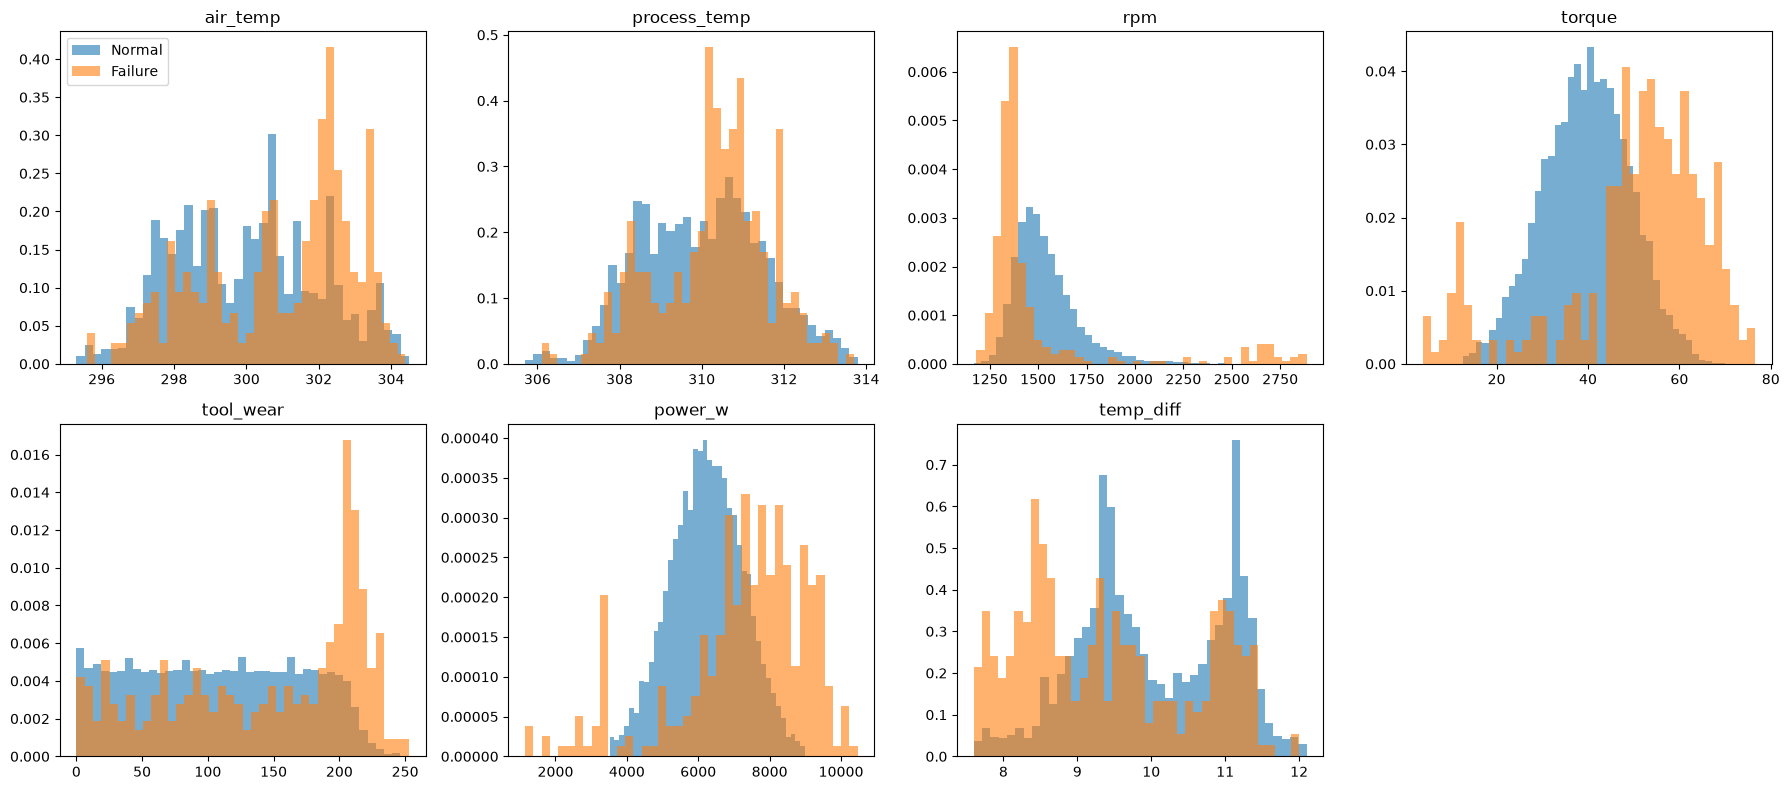

In [14]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, signals):
    ax.hist(normal[col], bins=40, alpha=0.6, density=True, label="Normal")
    ax.hist(failed[col], bins=40, alpha=0.6, density=True, label="Failure")
    ax.set_title(col)
axes.flat[0].legend()
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

In [15]:
eda["wear_bin"] = pd.cut(eda["tool_wear"], bins=[-1, 50, 100, 150, 200, 260])
print("Failure rate by tool wear:")
print((eda.groupby("wear_bin", observed=True)["Machine failure"].mean() * 100).round(2))

print("\nFailure rate by Type:")
print((eda.groupby("Type")["Machine failure"].mean() * 100).round(2))

Failure rate by tool wear:
wear_bin
(-1, 50]       2.17
(50, 100]      2.33
(100, 150]     2.18
(150, 200]     2.90
(200, 260]    15.49
Name: Machine failure, dtype: float64

Failure rate by Type:
Type
H    2.09
L    3.92
M    2.77
Name: Machine failure, dtype: float64


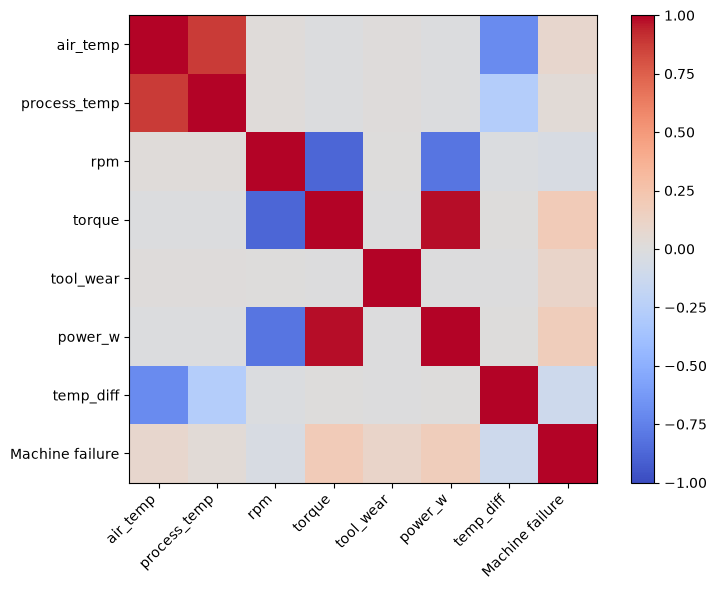

temp_diff      -0.112
rpm            -0.044
process_temp    0.036
air_temp        0.083
tool_wear       0.105
power_w         0.176
torque          0.191
Name: Machine failure, dtype: float64


In [16]:
corr = eda[signals + ["Machine failure"]].corr()

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)))
ax.set_yticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticklabels(corr.columns)
fig.colorbar(im)
plt.tight_layout()
plt.show()

print(corr["Machine failure"].drop("Machine failure").sort_values().round(3))

In [17]:
print("Outliers (IQR rule):")
for col in signals:
    q1, q3 = eda[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n = ((eda[col] < q1 - 1.5 * iqr) | (eda[col] > q3 + 1.5 * iqr)).sum()
    print(f"  {col:13s}: {n}")

print("\nRows with tool_wear = 0:", (eda["tool_wear"] == 0).sum())
print("Failure rate when tool_wear = 0:",
      round(eda.loc[eda["tool_wear"] == 0, "Machine failure"].mean() * 100, 2), "%")

Outliers (IQR rule):
  air_temp     : 0
  process_temp : 0
  rpm          : 418
  torque       : 69
  tool_wear    : 0
  power_w      : 60
  temp_diff    : 0

Rows with tool_wear = 0: 120
Failure rate when tool_wear = 0: 2.5 %
